In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# Create directory to save EDA charts
os.makedirs("../reports/figures", exist_ok=True)
print("Setup complete.")


Setup complete.


In [2]:
# Load datasets using semicolon separator
df_mat = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df_por = pd.read_csv("../data/raw/student-por.csv", sep=";")

print(f"Math Dataset Shape: {df_mat.shape}")
print(f"Portuguese Dataset Shape: {df_por.shape}\n")

print("--- Math Data Types & Nulls ---")
df_mat.info()


Math Dataset Shape: (395, 33)
Portuguese Dataset Shape: (649, 33)

--- Math Data Types & Nulls ---
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-nu

In [3]:
def run_quality_audit(df, name):
    print(f"=== QUALITY AUDIT: {name} ===")
    print(f"Total Rows: {len(df)} | Total Columns: {df.shape[1]}")
    print(f"Missing Values: {df.isnull().sum().sum()}")
    print(f"Exact Duplicate Rows: {df.duplicated().sum()}")
    
    # Check grade bounds (0 to 20)
    for col in ["G1", "G2", "G3"]:
        out_of_bounds = df[(df[col] < 0) | (df[col] > 20)]
        print(f"Out-of-bounds {col} (<0 or >20): {len(out_of_bounds)}")
        
    # Check zero final grades (G3 == 0)
    zero_g3 = df[df["G3"] == 0]
    print(f"Students with G3 == 0: {len(zero_g3)} ({len(zero_g3)/len(df)*100:.2f}%)")
    
    # Check at-risk count (G3 < 10)
    at_risk = df[df["G3"] < 10]
    print(f"Students with G3 < 10 (At-Risk): {len(at_risk)} ({len(at_risk)/len(df)*100:.2f}%)\n")

run_quality_audit(df_mat, "Mathematics (student-mat.csv)")
run_quality_audit(df_por, "Portuguese (student-por.csv)")


=== QUALITY AUDIT: Mathematics (student-mat.csv) ===
Total Rows: 395 | Total Columns: 33
Missing Values: 0
Exact Duplicate Rows: 0
Out-of-bounds G1 (<0 or >20): 0
Out-of-bounds G2 (<0 or >20): 0
Out-of-bounds G3 (<0 or >20): 0
Students with G3 == 0: 38 (9.62%)
Students with G3 < 10 (At-Risk): 130 (32.91%)

=== QUALITY AUDIT: Portuguese (student-por.csv) ===
Total Rows: 649 | Total Columns: 33
Missing Values: 0
Exact Duplicate Rows: 0
Out-of-bounds G1 (<0 or >20): 0
Out-of-bounds G2 (<0 or >20): 0
Out-of-bounds G3 (<0 or >20): 0
Students with G3 == 0: 15 (2.31%)
Students with G3 < 10 (At-Risk): 100 (15.41%)



In [4]:
print("=== MATH NUMERICAL SUMMARY ===")
display(df_mat.describe().T[["count", "mean", "std", "min", "50%", "max"]])

print("=== PORTUGUESE NUMERICAL SUMMARY ===")
display(df_por.describe().T[["count", "mean", "std", "min", "50%", "max"]])


=== MATH NUMERICAL SUMMARY ===


,count,mean,std,min,50%,max
age,395.0,16.696203,1.276043,15.0,17.0,22.0
Medu,395.0,2.749367,1.094735,0.0,3.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,4.0
studytime,395.0,2.035443,0.839240,1.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,5.0
goout,395.0,3.108861,1.113278,1.0,3.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,5.0


=== PORTUGUESE NUMERICAL SUMMARY ===


,count,mean,std,min,50%,max
age,649.0,16.744222,1.218138,15.0,17.0,22.0
Medu,649.0,2.514638,1.134552,0.0,2.0,4.0
Fedu,649.0,2.306626,1.099931,0.0,2.0,4.0
traveltime,649.0,1.568567,0.748660,1.0,1.0,4.0
studytime,649.0,1.930663,0.829510,1.0,2.0,4.0
failures,649.0,0.221880,0.593235,0.0,0.0,3.0
famrel,649.0,3.930663,0.955717,1.0,4.0,5.0
freetime,649.0,3.180277,1.051093,1.0,3.0,5.0
goout,649.0,3.184900,1.175766,1.0,3.0,5.0
Dalc,649.0,1.502311,0.924834,1.0,1.0,5.0


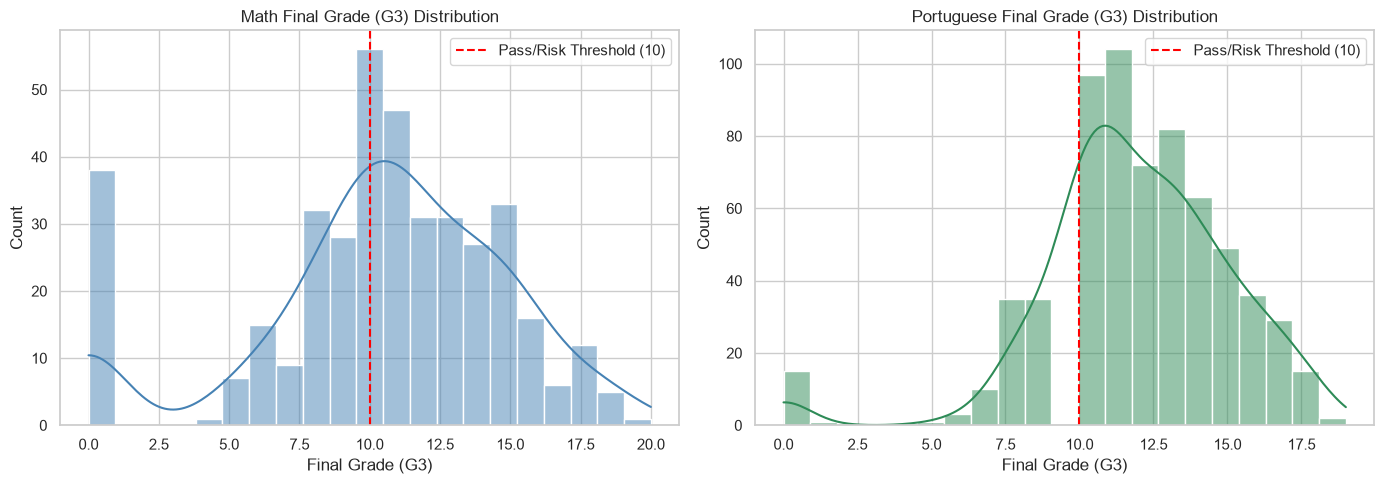

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# Math G3 Distribution
sns.histplot(df_mat["G3"], bins=21, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(10, color="red", linestyle="--", label="Pass/Risk Threshold (10)")
axes[0].set_title("Math Final Grade (G3) Distribution")
axes[0].set_xlabel("Final Grade (G3)")
axes[0].legend()

# Portuguese G3 Distribution
sns.histplot(df_por["G3"], bins=21, kde=True, ax=axes[1], color="seagreen")
axes[1].axvline(10, color="red", linestyle="--", label="Pass/Risk Threshold (10)")
axes[1].set_title("Portuguese Final Grade (G3) Distribution")
axes[1].set_xlabel("Final Grade (G3)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../reports/figures/01_g3_distributions.png", dpi=300)
plt.show()


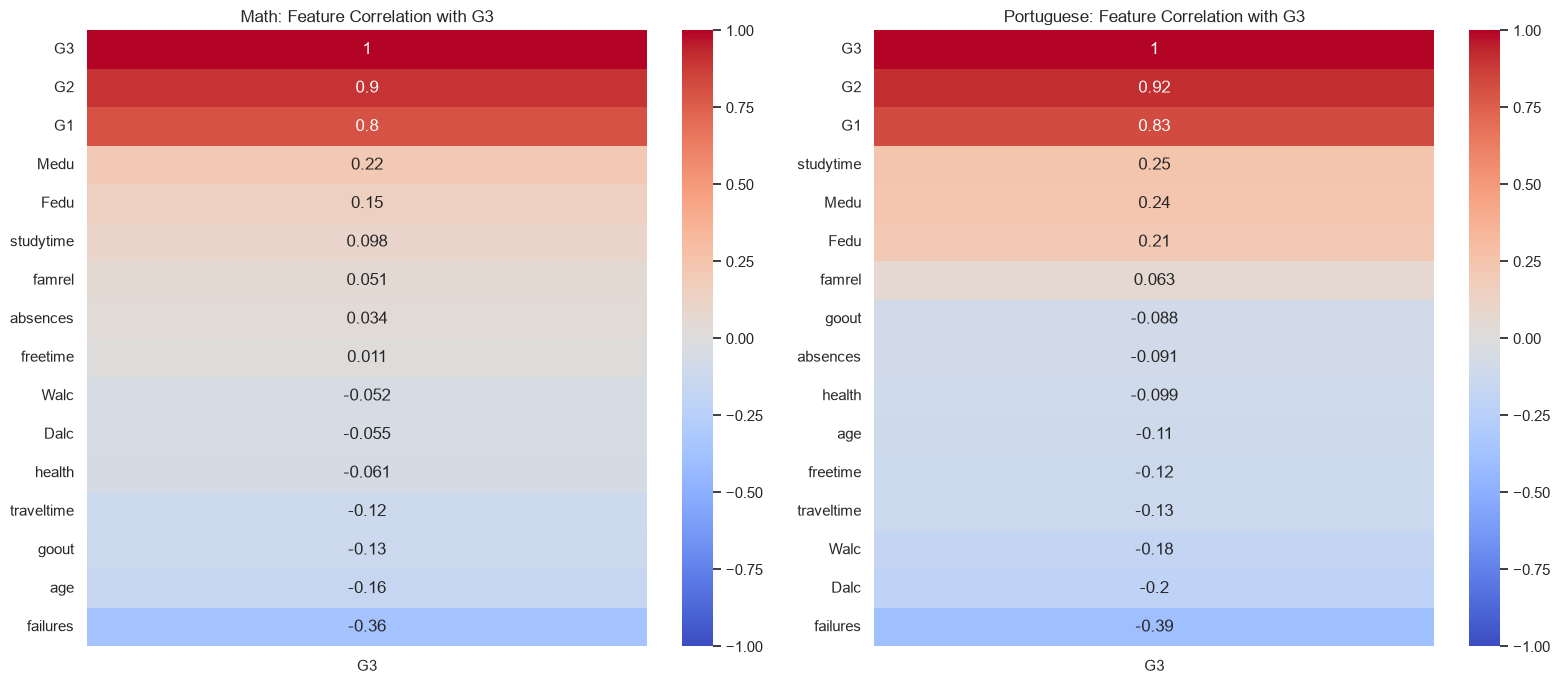

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Numerical correlations for Math
num_cols_mat = df_mat.select_dtypes(include=[np.number]).corr()
sns.heatmap(num_cols_mat[["G3"]].sort_values(by="G3", ascending=False), 
            annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Math: Feature Correlation with G3")

# Numerical correlations for Portuguese
num_cols_por = df_por.select_dtypes(include=[np.number]).corr()
sns.heatmap(num_cols_por[["G3"]].sort_values(by="G3", ascending=False), 
            annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Portuguese: Feature Correlation with G3")

plt.tight_layout()
plt.savefig("../reports/figures/02_g3_correlations.png", dpi=300)
plt.show()


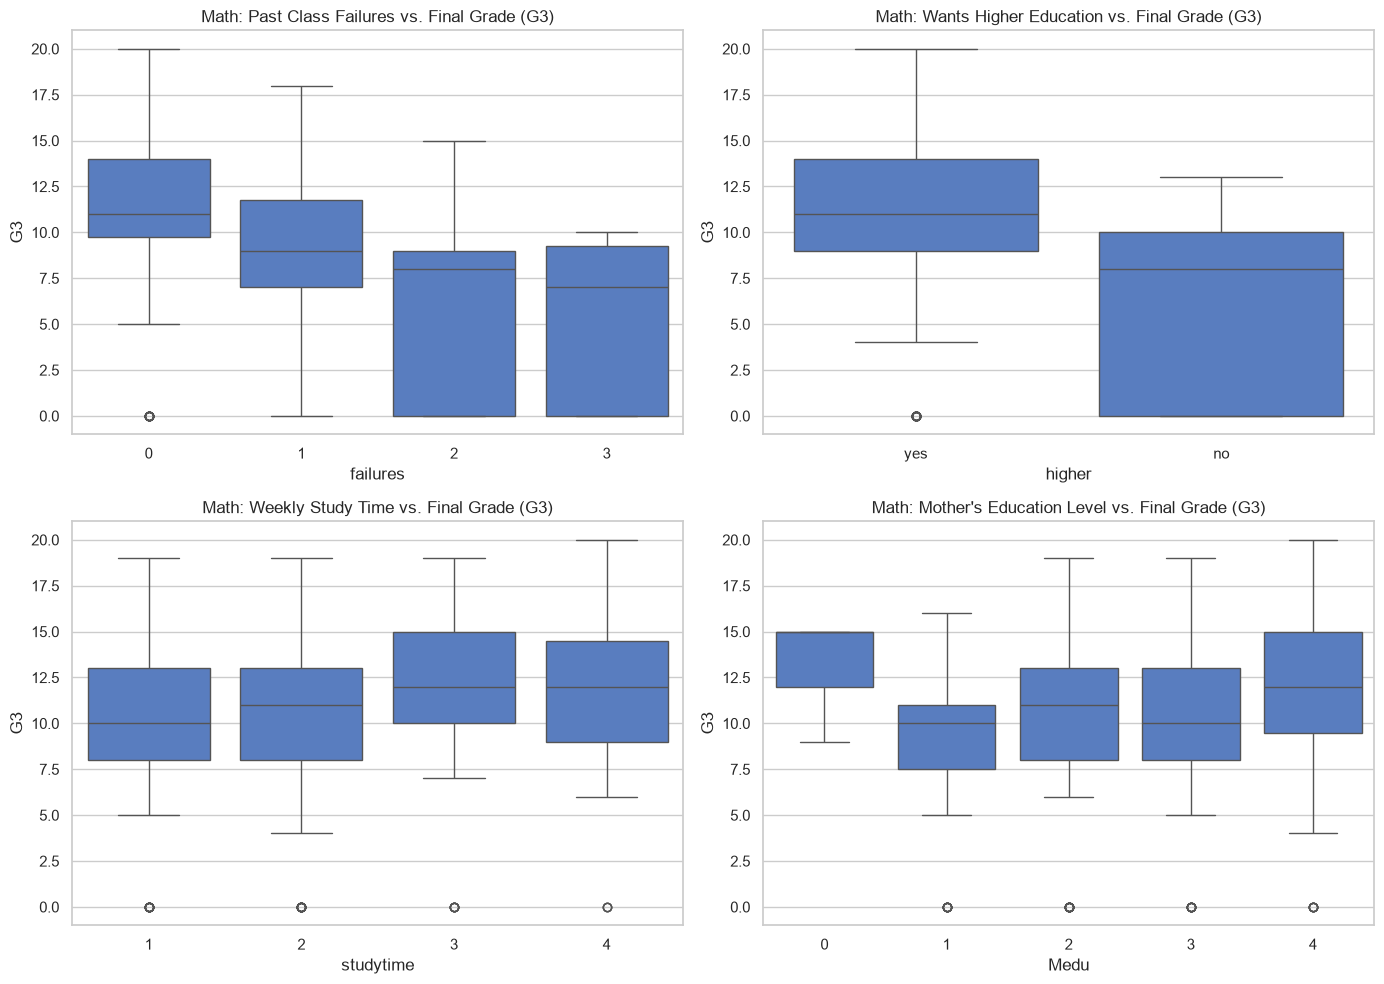

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Past Failures vs G3 (Math)
sns.boxplot(x="failures", y="G3", data=df_mat, ax=axes[0, 0])
axes[0, 0].set_title("Math: Past Class Failures vs. Final Grade (G3)")

# 2. Higher Education Aspiration vs G3 (Math)
sns.boxplot(x="higher", y="G3", data=df_mat, ax=axes[0, 1])
axes[0, 1].set_title("Math: Wants Higher Education vs. Final Grade (G3)")

# 3. Study Time vs G3 (Math)
sns.boxplot(x="studytime", y="G3", data=df_mat, ax=axes[1, 0])
axes[1, 0].set_title("Math: Weekly Study Time vs. Final Grade (G3)")

# 4. Mother's Education vs G3 (Math)
sns.boxplot(x="Medu", y="G3", data=df_mat, ax=axes[1, 1])
axes[1, 1].set_title("Math: Mother's Education Level vs. Final Grade (G3)")

plt.tight_layout()
plt.savefig("../reports/figures/03_key_drivers_vs_g3.png", dpi=300)
plt.show()


In [8]:
# Check G1 and G2 scores for students who received G3 == 0 in Math
zero_g3_math = df_mat[df_mat["G3"] == 0][["school", "sex", "age", "failures", "absences", "G1", "G2", "G3"]]
print("Sample of Math students with G3 == 0:")
display(zero_g3_math.head(10))


Sample of Math students with G3 == 0:


,school,sex,age,failures,absences,G1,G2,G3
128,GP,M,18,2,0,7,4,0
130,GP,F,15,2,0,12,0,0
131,GP,F,15,0,0,8,0,0
134,GP,M,15,0,0,9,0,0
135,GP,F,15,0,0,11,0,0
136,GP,M,17,0,0,10,0,0
137,GP,F,16,2,0,4,0,0
140,GP,M,15,0,0,7,9,0
144,GP,M,17,3,0,5,0,0
146,GP,F,15,3,0,6,7,0
